In [1]:
import sys
sys.path.insert(0, '../../../../')

import numpy as np
from gvns.rl.agents.offline.ppo_agent import PPOAgent
import matplotlib.pyplot as plt
import torch

# Load dataset

In [2]:
data_train = np.load("../../../datasets/param_controller_cleaned/train_clean.npz")
data_val = np.load("../../../datasets/param_controller_cleaned/val_clean.npz")

train_dataset = {
    "states": data_train["states"],
    "actions": data_train["actions"],
    "rewards": data_train["rewards"],
    "dones": data_train["dones"],
}

val_dataset = {
    "states": data_val["states"],
    "actions": data_val["actions"],
    "rewards": data_val["rewards"],
    "dones": data_val["dones"],
}

feature_names = list(data_train["feature_names"])
state_dim = len(feature_names)

print("State dim:", state_dim)
print("Train size:", train_dataset["states"].shape)

State dim: 23
Train size: (148265, 23)


# Init agent

In [3]:
agent = PPOAgent(
    state_dim=state_dim,
    n_actions=8,   # controller actions
    feature_names=feature_names,
    lr=3e-4,
    gamma=0.99,
    clip_eps=0.2,
    k_epochs=4,
    batch_size=256,
)

# Training loop

In [4]:
N_EPOCHS = 50

all_history = {
    "critic_loss": [],
    "entropy": [],
    "mean_value": [],
}

for epoch in range(N_EPOCHS):

    hist = agent.train_on_dataset(train_dataset, epochs=4)

    all_history["critic_loss"].append(hist["critic_loss"])
    all_history["entropy"].append(hist["entropy"])

    # evaluate average critic value
    states_tensor = torch.as_tensor(
        train_dataset["states"],
        dtype=torch.float32,
        device=agent.device
    )

    agent.model.eval()

    with torch.no_grad():
        _, values = agent.model(states_tensor)
        mean_value = values.mean().item()

    all_history["mean_value"].append(mean_value)

    print(
        f"Epoch {epoch+1} | "
        f"Critic Loss: {hist['critic_loss']:.4f} | "
        f"Entropy: {hist['entropy']:.4f} | "
        f"Mean Value: {mean_value:.4f}"
    )

Epoch 1 | Critic Loss: 0.2546 | Entropy: 2.0487 | Mean Value: -0.0086
Epoch 2 | Critic Loss: 0.1768 | Entropy: 2.0404 | Mean Value: -0.0120
Epoch 3 | Critic Loss: 0.1510 | Entropy: 2.0217 | Mean Value: 0.0170
Epoch 4 | Critic Loss: 0.1347 | Entropy: 2.0173 | Mean Value: -0.0239
Epoch 5 | Critic Loss: 0.1225 | Entropy: 1.9989 | Mean Value: 0.0530
Epoch 6 | Critic Loss: 0.1131 | Entropy: 1.9878 | Mean Value: -0.0477
Epoch 7 | Critic Loss: 0.1060 | Entropy: 1.9614 | Mean Value: -0.0248
Epoch 8 | Critic Loss: 0.1005 | Entropy: 1.9337 | Mean Value: 0.0087
Epoch 9 | Critic Loss: 0.0963 | Entropy: 1.8976 | Mean Value: -0.0227
Epoch 10 | Critic Loss: 0.0930 | Entropy: 1.8743 | Mean Value: -0.0325
Epoch 11 | Critic Loss: 0.0905 | Entropy: 1.8434 | Mean Value: 0.0049
Epoch 12 | Critic Loss: 0.0885 | Entropy: 1.8050 | Mean Value: 0.0007
Epoch 13 | Critic Loss: 0.0868 | Entropy: 1.7651 | Mean Value: -0.0049
Epoch 14 | Critic Loss: 0.0859 | Entropy: 1.7295 | Mean Value: -0.0143
Epoch 15 | Critic Lo

# Evaluation

## training curves

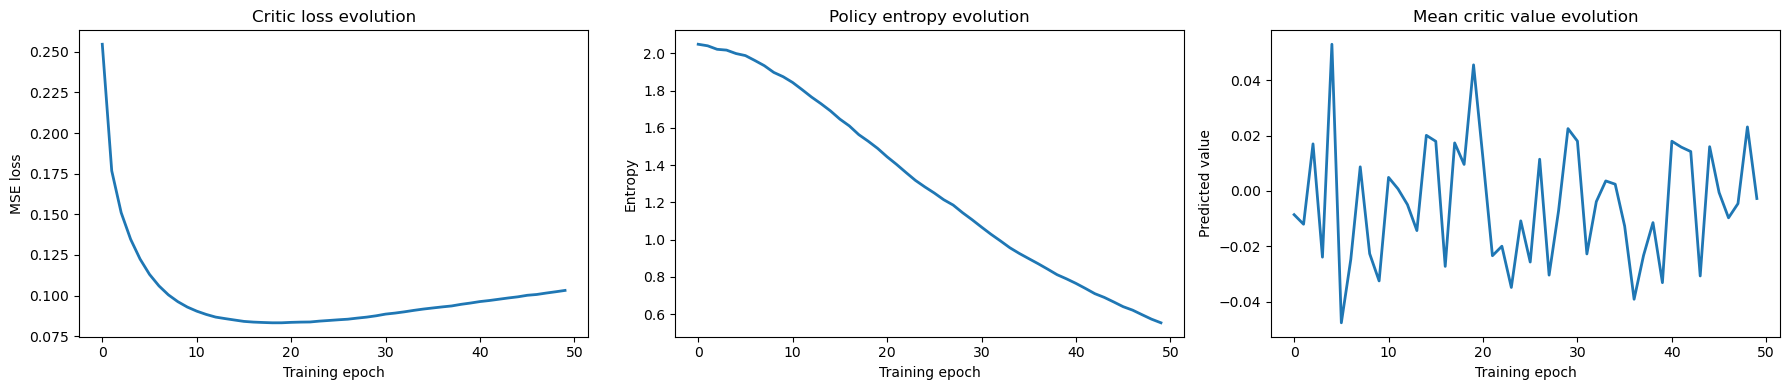

In [5]:
def plot_training_diagnostics(history):

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    # critic loss
    axes[0].plot(history["critic_loss"], linewidth=2)
    axes[0].set_title("Critic loss evolution")
    axes[0].set_xlabel("Training epoch")
    axes[0].set_ylabel("MSE loss")

    # entropy
    axes[1].plot(history["entropy"], linewidth=2)
    axes[1].set_title("Policy entropy evolution")
    axes[1].set_xlabel("Training epoch")
    axes[1].set_ylabel("Entropy")

    # mean value
    axes[2].plot(history["mean_value"], linewidth=2)
    axes[2].set_title("Mean critic value evolution")
    axes[2].set_xlabel("Training epoch")
    axes[2].set_ylabel("Predicted value")

    plt.tight_layout()
    plt.show()

plot_training_diagnostics(all_history)

## reward vs value function


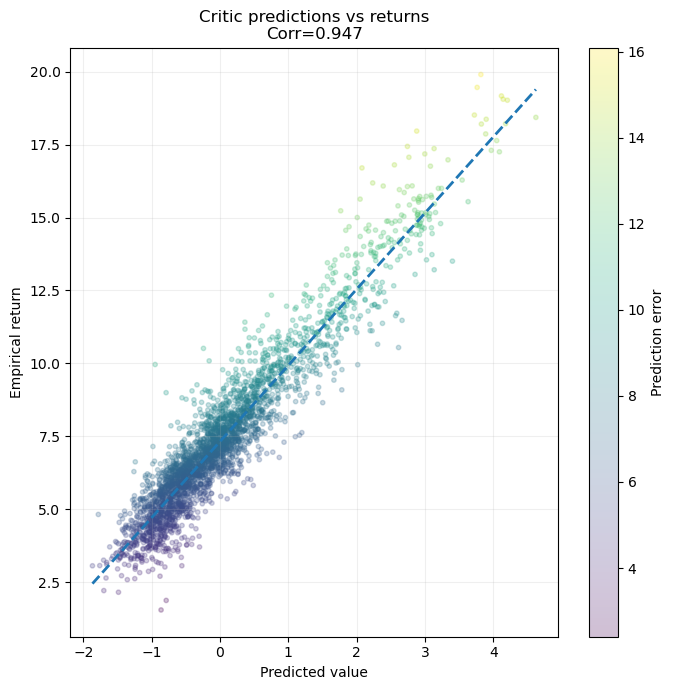

In [6]:
def plot_value_vs_return(agent, dataset, n_samples=3000):
    data = dataset

    states = torch.as_tensor(data["states"], dtype=torch.float32, device=agent.device)
    rewards = torch.as_tensor(data["rewards"], dtype=torch.float32, device=agent.device)
    dones = torch.as_tensor(data["dones"], dtype=torch.float32, device=agent.device)

    returns = agent._compute_returns(rewards, dones)

    idx = torch.randperm(len(states))[:n_samples]

    agent.model.eval()
    with torch.no_grad():
        _, values = agent.model(states[idx])
        values = values.squeeze().cpu().numpy()

    returns = returns[idx].cpu().numpy()

    plt.figure(figsize=(7,7))

    plt.scatter(
        values,
        returns,
        alpha=0.25,
        s=10,
        c=np.abs(values - returns),
        cmap="viridis"
    )

    coef = np.polyfit(values, returns, 1)
    poly1d_fn = np.poly1d(coef)

    x_line = np.linspace(values.min(), values.max(), 100)

    plt.plot(
        x_line,
        poly1d_fn(x_line),
        '--',
        linewidth=2,
        label='Trend'
    )
    plt.grid(alpha=0.2)

    corr = np.corrcoef(values, returns)[0,1]

    plt.title(f"Critic predictions vs returns\nCorr={corr:.3f}")

    plt.xlabel("Predicted value")
    plt.ylabel("Empirical return")

    plt.colorbar(label="Prediction error")

    plt.tight_layout()
    plt.show()

plot_value_vs_return(agent, train_dataset)

## Advantage Distribution

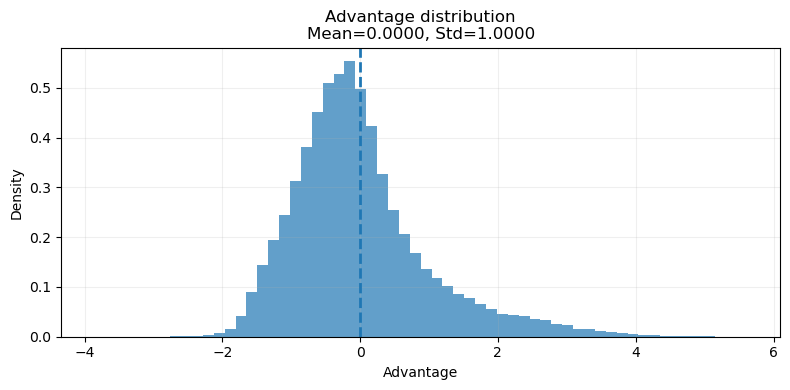

In [7]:
def plot_advantages(agent, dataset):

    data = dataset

    states = torch.as_tensor(
        data["states"],
        dtype=torch.float32,
        device=agent.device
    )

    rewards = torch.as_tensor(
        data["rewards"],
        dtype=torch.float32,
        device=agent.device
    )

    dones = torch.as_tensor(
        data["dones"],
        dtype=torch.float32,
        device=agent.device
    )

    returns = agent._compute_returns(rewards, dones)

    with torch.no_grad():
        _, values = agent.model(states)

    advantages = (returns - values.squeeze()).cpu().numpy()

    advantages = (
        advantages - advantages.mean()
    ) / (advantages.std() + 1e-8)

    mean_adv = advantages.mean()
    std_adv = advantages.std()

    plt.figure(figsize=(8,4))

    plt.hist(
        advantages,
        bins=60,
        density=True,
        alpha=0.7
    )

    plt.axvline(mean_adv, linestyle='--', linewidth=2)

    plt.title(
        f"Advantage distribution\n"
        f"Mean={mean_adv:.4f}, Std={std_adv:.4f}"
    )

    plt.xlabel("Advantage")
    plt.ylabel("Density")

    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

plot_advantages(agent, train_dataset)

# Validation evaluation

In [8]:
def evaluate_dataset(agent, dataset):
    data = dataset

    states = torch.as_tensor(data["states"], dtype=torch.float32, device=agent.device)
    actions = torch.as_tensor(data["actions"], dtype=torch.long, device=agent.device)
    rewards = torch.as_tensor(data["rewards"], dtype=torch.float32, device=agent.device)

    agent.model.eval()
    with torch.no_grad():
        logits, values = agent.model(states)
        dist = torch.distributions.Categorical(logits=logits)

        log_probs = dist.log_prob(actions)
        entropy = dist.entropy().mean().item()

    return {
        "log_prob_mean": log_probs.mean().item(),
        "value_mean": values.mean().item(),
        "reward_mean": rewards.mean().item(),
        "entropy": entropy,
    }

print("Train:", evaluate_dataset(agent, train_dataset))
print("Val:", evaluate_dataset(agent, val_dataset))

Train: {'log_prob_mean': -7.261051177978516, 'value_mean': -0.00274356990121305, 'reward_mean': 0.07351329922676086, 'entropy': 0.5534631609916687}
Val: {'log_prob_mean': -8.04811954498291, 'value_mean': -0.267416775226593, 'reward_mean': 0.06462211906909943, 'entropy': 0.49347367882728577}


# Save model

In [9]:
agent.save("models/ppo_param_controller.pt")
print("Model saved")

Model saved
